# Klasifikasi Kesegaran Ikan Berbasis Deep Learning

Notebook ini digunakan untuk melakukan klasifikasi kesegaran ikan menggunakan pendekatan transfer learning dan fine-tuning dengan arsitektur MobileNetV2 dan ResNet50.

Tahapan penelitian meliputi:

1. Persiapan dan pembagian dataset
2. Pra-pemrosesan citra menggunakan CLAHE
3. Pembangunan model MobileNetV2 dan ResNet50
4. Training tahap pertama (transfer learning)
5. Fine-tuning tahap kedua
6. Evaluasi pada data validasi internal
7. Evaluasi pada data eksternal
8. Perbandingan performa kedua model
9. Uji statistik McNemar
10. Analisis interpretabilitas menggunakan Grad-CAM

# A. Persiapan dan Dataset

Bagian ini mencakup proses penyiapan lingkungan komputasi, pengambilan dataset, penyeimbangan kelas, serta pembagian data menjadi data latih dan data validasi.

In [ ]:
# SEL 1: Fondasi Lingkungan (Import & Ekstrak)
import os, zipfile, glob, cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import cv2


from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.metrics import classification_report
from statsmodels.stats.contingency_tables import mcnemar

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.preprocessing import image_dataset_from_directory

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
✅ Dataset berhasil diekstrak!


## A.1. Persiapan Dataset

Dataset utama digunakan sebagai sumber data untuk proses pelatihan dan validasi model. Dataset terlebih dahulu diekstrak dari penyimpanan Google Drive sebelum dilakukan pengolahan lebih lanjut.

In [ ]:
zip_path = '/content/drive/MyDrive/tugas_akhir/dataset.zip'
extract_path = '/content/dataset'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("✅ Dataset berhasil diekstrak!")
else:
    print("❌ ZIP tidak ditemukan!")

## A.2. Penyeimbangan Kelas

Dataset disusun menjadi dua kelas, yaitu:

- **Segar**
- **Tidak Segar**

Jumlah citra pada kelas mayoritas disesuaikan dengan jumlah citra pada kelas minoritas agar proses pelatihan menggunakan distribusi kelas yang seimbang.

In [ ]:
# SEL 2: Pembagian Data Publik (Kaggle)
base_dir = '/content/dataset/dataset'

highly_fresh_paths = sorted([p for p in glob.glob(os.path.join(base_dir, 'Highly Fresh', '*')) if os.path.isfile(p)])
not_fresh_paths = sorted([p for p in glob.glob(os.path.join(base_dir, 'Not Fresh', '*')) if os.path.isfile(p)])

batas_jumlah = len(not_fresh_paths)
np.random.seed(42)
highly_fresh_terpilih = np.random.choice(highly_fresh_paths, size=batas_jumlah, replace=False).tolist()

paths_biner = highly_fresh_terpilih + not_fresh_paths
labels_biner = [0] * batas_jumlah + [1] * batas_jumlah
CLASS_NAMES = ['Segar', 'Tidak Segar']


✅ Data dikunci: Latih (2089), Validasi (523)


## A.3. Pembagian Data Latih dan Validasi

Data yang telah diseimbangkan kemudian dibagi menjadi data latih dan data validasi menggunakan stratified split dengan rasio 80:20.

Pembagian dilakukan secara stratified untuk mempertahankan proporsi masing-masing kelas pada data latih dan validasi.

In [ ]:
train_p_biner, val_p_biner, train_l_biner, val_l_biner = train_test_split(
    paths_biner, labels_biner, test_size=0.2, random_state=42, stratify=labels_biner
)
print(f"✅ Data dikunci: Latih ({len(train_p_biner)}), Validasi ({len(val_p_biner)})")

# B. Pra-pemrosesan Citra

Tahap pra-pemrosesan bertujuan untuk menyeragamkan ukuran citra serta meningkatkan kualitas informasi visual yang digunakan oleh model.

Pada penelitian ini digunakan metode **Contrast Limited Adaptive Histogram Equalization (CLAHE)** untuk meningkatkan kontras citra.

## B.1. Konfigurasi Pra-pemrosesan

In [ ]:
# SEL 3: Pipeline Prapemrosesan (CLAHE 256x256)
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
EXTERNAL_TEST_DIR = '/content/drive/MyDrive/tugas_akhir/data_bandeng_crop'

Found 128 files belonging to 2 classes.
✅ Pipeline Dataset Siap!


## B.2. Penerapan CLAHE

CLAHE diterapkan pada kanal luminansi citra dalam ruang warna LAB. Proses ini dilakukan setelah citra diubah ukurannya menjadi 256 × 256 piksel.

In [ ]:
def apply_clahe(image):
    image_uint8 = image.astype(np.uint8)
    lab = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB).astype(np.float32)

def process_path(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.numpy_function(func=apply_clahe, inp=[img], Tout=tf.float32)
    img.set_shape((256, 256, 3))
    return img, label

## B.3. Visualisasi Pra-pemrosesan

Untuk memverifikasi proses pra-pemrosesan, dilakukan visualisasi perbandingan antara citra asli dan citra setelah penerapan CLAHE.

In [ ]:
# Ambil 1 contoh gambar dari data latih (indeks ke-0)
sample_path = train_p_biner[0]

# Baca dan seragamkan gambar ke 256x256
img_asli = cv2.imread(sample_path)
img_asli = cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB)
img_asli_resized = cv2.resize(img_asli, (256, 256))

# Terapkan fungsi CLAHE milikmu dari Sel 3
img_clahe = apply_clahe(img_asli_resized)

# Plot Gambar Berdampingan
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Sisi Kiri (Asli)
axes[0].imshow(img_asli_resized.astype(np.uint8))
axes[0].set_title("Citra Asli (256x256)")
axes[0].axis("off")

# Sisi Kanan (CLAHE)
axes[1].imshow(img_clahe.astype(np.uint8))
axes[1].set_title("Hasil CLAHE (256x256)")
axes[1].axis("off")

plt.tight_layout()

# Simpan ke Google Drive tempat folder hasil eksperimenmu
save_path = '/content/drive/MyDrive/Hasil_Eksperimen_Bandeng/Gambar_4_1_CLAHE.png'
plt.savefig(save_path, dpi=300)
print(f"✅ Gambar 4.1 berhasil disimpan di: {save_path}")
plt.show()

## B.4. Pembentukan Pipeline Dataset

Setelah pra-pemrosesan didefinisikan, citra diproses menggunakan pipeline `tf.data` untuk data latih dan validasi.

Selain dataset internal, disiapkan pula dataset eksternal yang digunakan untuk menguji kemampuan generalisasi model terhadap data di luar dataset pelatihan.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = tf.data.Dataset.from_tensor_slices((train_p_biner, train_l_biner)).map(process_path, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_dataset = tf.data.Dataset.from_tensor_slices((val_p_biner, val_l_biner)).map(process_path, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

ext_ds_raw = image_dataset_from_directory(EXTERNAL_TEST_DIR, image_size=IMG_SIZE, batch_size=None, label_mode='binary', shuffle=False)
external_dataset = ext_ds_raw.map(lambda x, y: (tf.numpy_function(apply_clahe, [x], tf.float32), y), num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
print("✅ Pipeline Dataset Siap!")

# C. Pembangunan Model

Penelitian menggunakan dua arsitektur convolutional neural network berbasis transfer learning, yaitu:

1. MobileNetV2
2. ResNet50

Kedua model menggunakan bobot pretrained ImageNet sebagai feature extractor pada tahap awal.

## C.1. Arsitektur MobileNetV2

In [ ]:
# SEL 4: Pembangunan Arsitektur Model Dasar (MENGEMBALIKAN SETINGAN TERBAIK)
from tensorflow.keras.applications import mobilenet_v2, resnet50

def build_mb():
    inputs = Input(shape=(256, 256, 3))
    x = mobilenet_v2.preprocess_input(inputs) # Native Normalization
    base_model = MobileNetV2(input_tensor=x, include_top=False, weights='imagenet')
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x) # <-- Mengembalikan Jembatan Fitur Utama!
    x = Dropout(0.5)(x)                  # <-- Dikunci kembali ke 0.5 sesuai file lama
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

model_mb = build_mb()
print("✅ Arsitektur Model Dasar Berhasil Dikembalikan ke Setingan Terbaik (Skor Tinggi)!")

/tmp/ipykernel_625/3639428157.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_tensor=x, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
✅ Arsitektur Model Dasar Berhasil Dikembalikan ke Setingan Terbaik (Skor Tinggi)!


## C.2. Arsitektur ResNet50

In [ ]:
def build_rs():
    inputs = Input(shape=(256, 256, 3))
    x = resnet50.preprocess_input(inputs) # Native Normalization
    base_model = ResNet50(input_tensor=x, include_top=False, weights='imagenet')
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x) # <-- Mengembalikan Jembatan Fitur Utama!
    x = Dropout(0.5)(x)                  # <-- Dikunci kembali ke 0.5 sesuai file lama
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

model_rs = build_rs()
print("✅ Arsitektur Model Dasar Berhasil Dikembalikan ke Setingan Terbaik (Skor Tinggi)!")

# D. Konfigurasi Training

Sebelum proses training dilakukan, model dikonfigurasi menggunakan optimizer, fungsi loss, serta callback untuk mengontrol proses pembelajaran.

Training dilakukan dalam dua tahap:

- **Fase 1:** transfer learning dengan base model dibekukan
- **Fase 2:** fine-tuning dengan sebagian layer backbone dibuka kembali

# E. Training Fase 1 — Transfer Learning

Pada fase pertama, backbone MobileNetV2 dan ResNet50 menggunakan bobot pretrained ImageNet dan layer feature extractor dibekukan.

Training difokuskan pada lapisan klasifikasi yang ditambahkan pada bagian akhir model.

In [ ]:
# SEL 5: 🚀 [TRAINING FASE 1] Pre-Training & Setup Callbacks Akurasi Tinggi
SAVE_DIR = '/content/drive/MyDrive/tugas_akhir'
os.makedirs(SAVE_DIR, exist_ok=True)
# --- PENCATAT WAKTU FASE 1 MULAI ---
start_fase1 = time.time()

def get_callbacks(name):
    # Menyimpan model dengan akurasi validasi tertinggi
    cp = ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, f"saved_models{name}.h5"),
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=0
    )

    # Sinkronisasi Reducer persis seperti eksperimen lama Anda yang sukses
    lr_reducer = ReduceLROnPlateau(
        monitor='val_accuracy',
        mode='max',
        factor=0.2,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )

    # Sinkronisasi Early Stopping persis seperti eksperimen lama Anda yang sukses
    early_stop = EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    )

    return [cp, lr_reducer, early_stop]

EPOCHS = 30
print("=== ASISTEN CALLBACKS AKTIF (SINKRONISASI EKSPERIMEN LAMA) ===")
print("Memantau: val_accuracy | Patience ES: 12 | Patience LR: 8\n")

=== ASISTEN CALLBACKS AKTIF (SINKRONISASI EKSPERIMEN LAMA) ===
Memantau: val_accuracy | Patience ES: 12 | Patience LR: 8

🔥 [FASE 1] PRE-TRAINING MOBILENETV2...
Epoch 1/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.5141 - loss: 0.7680

66/66 ━━━━━━━━━━━━━━━━━━━━ 74s 803ms/step - accuracy: 0.5337 - loss: 0.7393 - val_accuracy: 0.6252 - val_loss: 0.6543 - learning_rate: 1.0000e-04
Epoch 2/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.6256 - loss: 0.6490

66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 167ms/step - accuracy: 0.6051 - loss: 0.6637 - val_accuracy: 0.6597 - val_loss: 0.6267 - learning_rate: 1.0000e-04
Epoch 3/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.6519 - loss: 0.6192

66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 143ms/step - accuracy: 0.6410 - loss: 0.6271 - val_accuracy: 0.6807 - val_loss: 0.6116 - learning_rate: 1.0000e-04
Epoch 4/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.6728 - loss: 0.5963

66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 163ms/step - accuracy: 0.6692 - loss: 0.6076 - val_accuracy: 0.7017 - val_loss: 0.5988 - learning_rate: 1.0000e-04
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 150ms/step - accuracy: 0.7042 - loss: 0.5747 - val_accuracy: 0.6807 - val_loss: 0.5898 - learning_rate: 1.0000e-04
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 148ms/step - accuracy: 0.7042 - loss: 0.5588 - val_accuracy: 0.6902 - val_loss: 0.5837 - learning_rate: 1.0000e-04
Epoch 7/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.7218 - loss: 0.5310

66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step - accuracy: 0.7180 - loss: 0.5412 - val_accuracy: 0.7113 - val_loss: 0.5755 - learning_rate: 1.0000e-04
Epoch 8/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - accuracy: 0.7415 - loss: 0.5238 - val_accuracy: 0.7113 - val_loss: 0.5680 - learning_rate: 1.0000e-04
Epoch 9/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 164ms/step - accuracy: 0.7382 - loss: 0.5228 - val_accuracy: 0.7055 - val_loss: 0.5609 - learning_rate: 1.0000e-04
Epoch 10/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.7706 - loss: 0.4902

... (29 outputs left out)

66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 194ms/step - accuracy: 0.9268 - loss: 0.2034 - val_accuracy: 0.8222 - val_loss: 0.3998 - learning_rate: 1.0000e-04
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 150ms/step - accuracy: 0.9469 - loss: 0.1931 - val_accuracy: 0.8069 - val_loss: 0.3939 - learning_rate: 1.0000e-04
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 168ms/step - accuracy: 0.9445 - loss: 0.1826 - val_accuracy: 0.8203 - val_loss: 0.3915 - learning_rate: 1.0000e-04
Epoch 8/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 163ms/step - accuracy: 0.9459 - loss: 0.1784 - val_accuracy: 0.8069 - val_loss: 0.3978 - learning_rate: 1.0000e-04
Epoch 9/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 157ms/step - accuracy: 0.9454 - loss: 0.1831 - val_accuracy: 0.8126 - val_loss: 0.3924 - learning_rate: 1.0000e-04
Epoch 10/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 21s 164ms/step - accuracy: 0.9512 - loss: 0.1703 - val_accuracy: 0.8184 - val_loss: 0.3921 - learning_rate: 1.0000e-04
Epoch 11/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9

66/66 ━━━━━━━━━━━━━━━━━━━━ 23s 195ms/step - accuracy: 0.9536 - loss: 0.1624 - val_accuracy: 0.8241 - val_loss: 0.3924 - learning_rate: 1.0000e-04
Epoch 12/30
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.9584 - loss: 0.1511

66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 188ms/step - accuracy: 0.9540 - loss: 0.1567 - val_accuracy: 0.8298 - val_loss: 0.3862 - learning_rate: 1.0000e-04
Epoch 13/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 185ms/step - accuracy: 0.9588 - loss: 0.1508 - val_accuracy: 0.8203 - val_loss: 0.3916 - learning_rate: 1.0000e-04
Epoch 14/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 166ms/step - accuracy: 0.9574 - loss: 0.1549 - val_accuracy: 0.8145 - val_loss: 0.3878 - learning_rate: 1.0000e-04
Epoch 15/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 159ms/step - accuracy: 0.9560 - loss: 0.1454 - val_accuracy: 0.8222 - val_loss: 0.3905 - learning_rate: 1.0000e-04
Epoch 16/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 164ms/step - accuracy: 0.9636 - loss: 0.1395 - val_accuracy: 0.8088 - val_loss: 0.4051 - learning_rate: 1.0000e-04
Epoch 17/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 144ms/step - accuracy: 0.9617 - loss: 0.1418 - val_accuracy: 0.8279 - val_loss: 0.3877 - learning_rate: 1.0000e-04
Epoch 18/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 152ms/step - accuracy

66/66 ━━━━━━━━━━━━━━━━━━━━ 23s 210ms/step - accuracy: 0.9722 - loss: 0.1180 - val_accuracy: 0.8337 - val_loss: 0.3884 - learning_rate: 2.0000e-05
Epoch 22/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 166ms/step - accuracy: 0.9698 - loss: 0.1172 - val_accuracy: 0.8337 - val_loss: 0.3870 - learning_rate: 2.0000e-05
Epoch 23/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 167ms/step - accuracy: 0.9674 - loss: 0.1135 - val_accuracy: 0.8279 - val_loss: 0.3875 - learning_rate: 2.0000e-05
Epoch 24/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 163ms/step - accuracy: 0.9718 - loss: 0.1126 - val_accuracy: 0.8317 - val_loss: 0.3870 - learning_rate: 2.0000e-05
Epoch 25/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 163ms/step - accuracy: 0.9770 - loss: 0.1117 - val_accuracy: 0.8298 - val_loss: 0.3883 - learning_rate: 2.0000e-05
Epoch 26/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 20s 156ms/step - accuracy: 0.9789 - loss: 0.1108 - val_accuracy: 0.8298 - val_loss: 0.3868 - learning_rate: 2.0000e-05
Epoch 27/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy

## E.1. Training MobileNetV2 — Fase 1

In [ ]:
model_mb = build_mb()

# --- KOMPUTASI WAKTU MOBILENETV2 FASE 1 ---
print("🔥 [FASE 1] PRE-TRAINING MOBILENETV2...")
start_mb_f1 = time.time()
history_mb_1 = model_mb.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=get_callbacks('MB_Pretrain'))
end_mb_f1 = time.time()
durasi_mb_f1 = end_mb_f1 - start_mb_f1
print(f"⏱️ TOTAL WAKTU TRAINING MOBILENETV2 FASE 1: {int(durasi_mb_f1 // 60)} menit {int(durasi_mb_f1 % 60)} detik\n")

## E.2. Training ResNet50 — Fase 1

In [ ]:
model_rs = build_rs()

# --- KOMPUTASI WAKTU RESNET50 FASE 1 ---
print("🔥 [FASE 1] PRE-TRAINING RESNET50...")
start_rs_f1 = time.time()
history_rs_1 = model_rs.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=get_callbacks('RS_Pretrain'))
end_rs_f1 = time.time()
durasi_rs_f1 = end_rs_f1 - start_rs_f1
print(f"⏱️ TOTAL WAKTU TRAINING RESNET50 FASE 1: {int(durasi_rs_f1 // 60)} menit {int(durasi_rs_f1 % 60)} detik")

# F. Evaluasi Training Fase 1

Evaluasi fase pertama dilakukan untuk mengetahui performa awal kedua model sebelum proses fine-tuning.

Evaluasi meliputi:

- kurva akurasi dan loss,
- confusion matrix,
- ROC curve,
- AUC,
- serta classification report.

In [ ]:
OUTPUT_DIR = '/content/drive/MyDrive/Hasil_Eksperimen_Bandeng'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Mengunci deklarasi variabel agar bebas dari NameError
CLASS_NAMES = ['Segar', 'Tidak Segar']

In [ ]:
# 1. Menggambar Grafik Akurasi & Loss Fase 1
def plot_history_f1(hist, title, filename):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist.history['accuracy'], label='Train Acc')
    plt.plot(hist.history['val_accuracy'], label='Val Acc')
    plt.legend(); plt.title(f'{title} - Accuracy')
    plt.subplot(1, 2, 2)
    plt.plot(hist.history['loss'], label='Train Loss')
    plt.plot(hist.history['val_loss'], label='Val Loss')
    plt.legend(); plt.title(f'{title} - Loss')
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

print("[INFO] Menggambar Kurva Latihan Fase 1...")
plot_history_f1(history_mb_1, "MobileNetV2 (Fase 1)", "Kurva_MB_Fase1.png")
plot_history_f1(history_rs_1, "ResNet50 (Fase 1)", "Kurva_RS_Fase1.png")

In [ ]:
# 2. Ambil Data Validasi & Ekstraksi Probabilitas
y_true_val = np.concatenate([y for x, y in val_dataset], axis=0)
prob_mb_val = model_mb.predict(val_dataset).ravel()
prob_rs_val = model_rs.predict(val_dataset).ravel()

pred_mb_val = (prob_mb_val >= 0.5).astype(int)
pred_rs_val = (prob_rs_val >= 0.5).astype(int)

# 3. Gambar Confusion Matrix Biner
def plot_cm_f1(y_true, y_pred, title, colormap, filename):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=colormap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 16})
    plt.title(title); plt.ylabel('Aktual (Label Sebenarnya)'); plt.xlabel('Prediksi (Keputusan AI)')
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

print("\n[INFO] Menggambar Grafik Matriks Validasi Data Publik (Mendeley Data)...")
plot_cm_f1(y_true_val, pred_mb_val, "CM MobileNetV2 (Validasi Data Publik (Mendeley Data))", "Blues", "CM_Val_MB.png")
plot_cm_f1(y_true_val, pred_rs_val, "CM ResNet50 (Validasi Data Publik (Mendeley Data))", "Greens", "CM_Val_RS.png")

[INFO] Menggambar Kurva Latihan Fase 1...


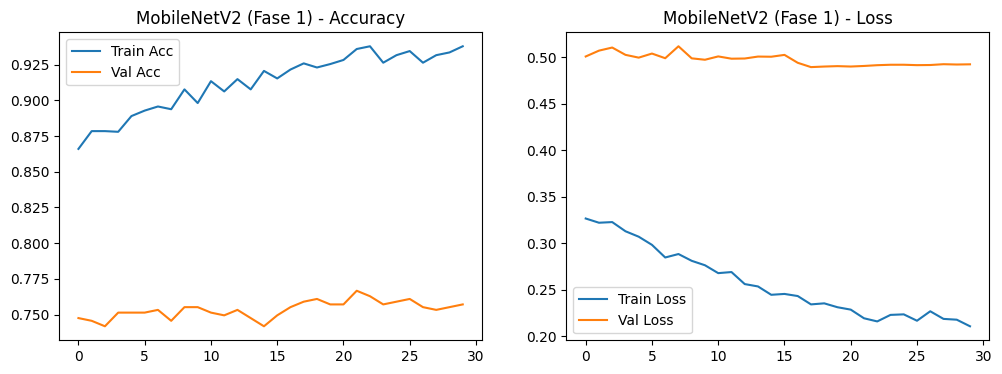

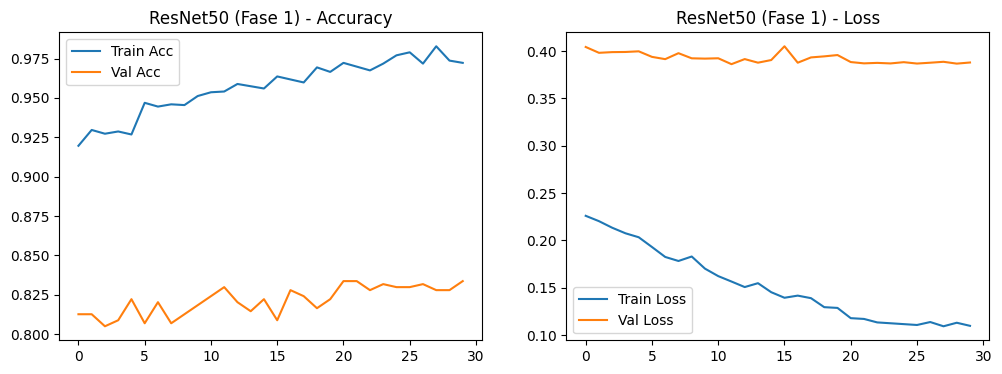

17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 539ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 336ms/step

[INFO] Menggambar Grafik Matriks Validasi Kaggle...


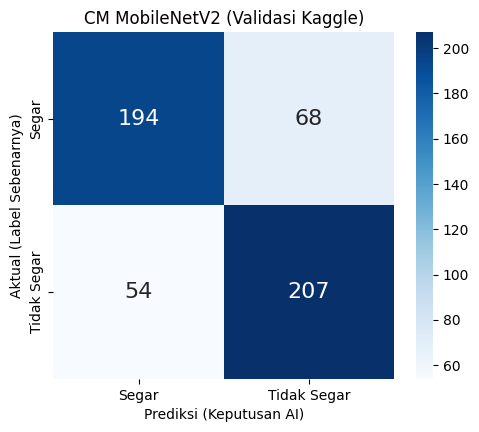

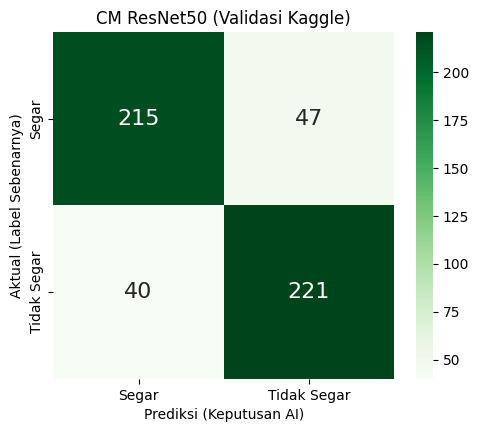


[INFO] Menggambar Kurva ROC Perbandingan Fase 1...


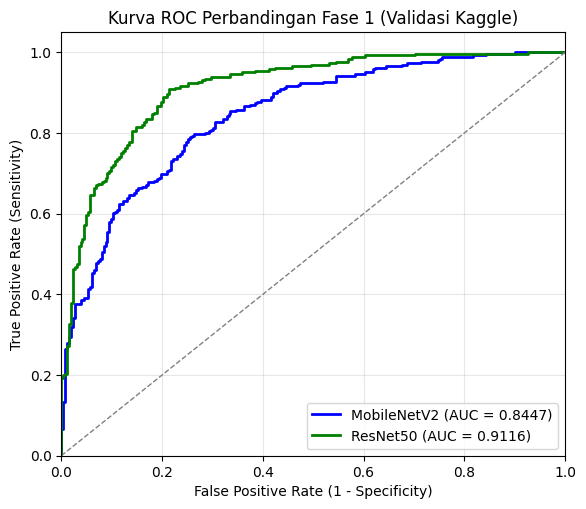

In [ ]:
# 4. Menggambar Kurva ROC Perbandingan Fase 1
print("\n[INFO] Menggambar Kurva ROC Perbandingan Fase 1...")
fpr_mb, tpr_mb, _ = roc_curve(y_true_val, prob_mb_val)
fpr_rs, tpr_rs, _ = roc_curve(y_true_val, prob_rs_val)
auc_mb = auc(fpr_mb, tpr_mb)
auc_rs = auc(fpr_rs, tpr_rs)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr_mb, tpr_mb, color='blue', lw=2, label=f'MobileNetV2 (AUC = {auc_mb:.4f})')
plt.plot(fpr_rs, tpr_rs, color='green', lw=2, label=f'ResNet50 (AUC = {auc_rs:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Kurva ROC Perbandingan Fase 1 (Validasi Kaggle)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "ROC_Comparison_Fase1.png"), dpi=300, bbox_inches='tight')
plt.show()

## F.1. Perbandingan Performa Fase 1

Hasil evaluasi MobileNetV2 dan ResNet50 pada fase pertama dibandingkan berdasarkan metrik klasifikasi yang diperoleh dari data validasi internal.

In [ ]:
# 5. Rekapitulasi Teks F1-Score & Laporan Klasifikasi
def generate_recap_text_f1(y_true, y_pred, model_name, fase):
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
    df = pd.DataFrame(report).transpose().round(4)
    # File .csv tetap diamankan otomatis ke Drive di latar belakang
    df.to_csv(os.path.join(OUTPUT_DIR, f"Rekap_{fase}_{model_name}.csv"))

    print("\n" + "="*65)
    print(f"📊 TABEL REKAPITULASI FASE 1 - {model_name.upper()} (VALIDASI DATA PUBLIK)")
    print("="*65)
    print(df.to_string()) # Mencetak dalam bentuk tabel teks biner biasa, bersih & rapi

generate_recap_text_f1(y_true_val, pred_mb_val, "MobileNetV2", "Fase1_Validasi")
generate_recap_text_f1(y_true_val, pred_rs_val, "ResNet50", "Fase1_Validasi")


📊 TABEL REKAPITULASI FASE 1 - MOBILENETV2 (VALIDASI KAGGLE)
              precision  recall  f1-score   support
Segar            0.7823  0.7405    0.7608  262.0000
Tidak Segar      0.7527  0.7931    0.7724  261.0000
accuracy         0.7667  0.7667    0.7667    0.7667
macro avg        0.7675  0.7668    0.7666  523.0000
weighted avg     0.7675  0.7667    0.7666  523.0000

📊 TABEL REKAPITULASI FASE 1 - RESNET50 (VALIDASI KAGGLE)
              precision  recall  f1-score   support
Segar            0.8431  0.8206    0.8317  262.0000
Tidak Segar      0.8246  0.8467    0.8355  261.0000
accuracy         0.8337  0.8337    0.8337    0.8337
macro avg        0.8339  0.8337    0.8336  523.0000
weighted avg     0.8339  0.8337    0.8336  523.0000


# G. Training Fase 2 — Fine-Tuning

Setelah memperoleh bobot awal dari transfer learning, dilakukan fine-tuning untuk menyesuaikan feature extractor dengan karakteristik citra ikan pada dataset penelitian.

Pada tahap ini, sebagian layer backbone dibuka kembali dan model dilatih menggunakan learning rate yang lebih kecil.

## G.1. Modifikasi dan Unfreezing Model

In [ ]:
# SEL 7: Modifikasi Arsitektur Anti-Stagnasi
def unfreeze_anti_stagnation(model, layers_to_unfreeze=30):
    model.trainable = True
    freeze_until = len(model.layers) - (layers_to_unfreeze + 4)
    for i, layer in enumerate(model.layers):
        if i < freeze_until:
            layer.trainable = False
        elif isinstance(layer, tf.keras.layers.BatchNormalization) or 'batch_normalization' in layer.name.lower():
            layer.trainable = False
        else:
            layer.trainable = True

    optimizer = tf.keras.optimizers.AdamW(learning_rate=2e-5, weight_decay=1e-3)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

model_mb = unfreeze_anti_stagnation(model_mb, 30)
model_rs = unfreeze_anti_stagnation(model_rs, 30)
print("✅ Arsitektur Siap untuk Fine-Tuning Anti-Stagnasi!")

✅ Arsitektur Siap untuk Fine-Tuning Anti-Stagnasi!


In [ ]:
# SEL 8: 🚀 [TRAINING FASE 2] Fine-Tuning Lokal

# --- PENCATAT WAKTU FASE 2 MULAI ---
start_fase2 = time.time()

EPOCHS_FT = 40

## G.2. Training MobileNetV2 — Fase 2

In [ ]:
# --- KOMPUTASI WAKTU MOBILENETV2 FASE 2 ---
print("🔥 [FASE 2] FINE-TUNING MOBILENETV2 (Data Lokal)...")
start_mb_f2 = time.time()
history_mb_2 = model_mb.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS_FT, callbacks=get_callbacks('MB_FineTune_Lokal'))
end_mb_f2 = time.time()
durasi_mb_f2 = end_mb_f2 - start_mb_f2
print(f"⏱️ TOTAL WAKTU TRAINING MOBILENETV2 FASE 2: {int(durasi_mb_f2 // 60)} menit {int(durasi_mb_f2 % 60)} detik\n")

## G.3. Training ResNet50 — Fase 2

In [ ]:
# --- KOMPUTASI WAKTU RESNET50 FASE 2 ---
print("🔥 [FASE 2] FINE-TUNING RESNET50 (Data Lokal)...")
start_rs_f2 = time.time()
history_rs_2 = model_rs.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS_FT, callbacks=get_callbacks('RS_FineTune_Lokal'))
end_rs_f2 = time.time()
durasi_rs_f2 = end_rs_f2 - start_rs_f2
print(f"⏱️ TOTAL WAKTU TRAINING RESNET50 FASE 2: {int(durasi_rs_f2 // 60)} menit {int(durasi_rs_f2 % 60)} detik")

🔥 [FASE 2] FINE-TUNING MOBILENETV2 (Data Lokal)...
Epoch 1/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.8815 - loss: 0.2722

66/66 ━━━━━━━━━━━━━━━━━━━━ 47s 476ms/step - accuracy: 0.8928 - loss: 0.2593 - val_accuracy: 0.7706 - val_loss: 0.5070 - learning_rate: 2.0000e-05
Epoch 2/40
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.9387 - loss: 0.1960

66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 162ms/step - accuracy: 0.9387 - loss: 0.1943 - val_accuracy: 0.7744 - val_loss: 0.4964 - learning_rate: 2.0000e-05
Epoch 3/40
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.9493 - loss: 0.1583

66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 146ms/step - accuracy: 0.9416 - loss: 0.1677 - val_accuracy: 0.7992 - val_loss: 0.4960 - learning_rate: 2.0000e-05
Epoch 4/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 147ms/step - accuracy: 0.9521 - loss: 0.1522 - val_accuracy: 0.7878 - val_loss: 0.4822 - learning_rate: 2.0000e-05
Epoch 5/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy: 0.9689 - loss: 0.1216 - val_accuracy: 0.7878 - val_loss: 0.4875 - learning_rate: 2.0000e-05
Epoch 6/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy: 0.9665 - loss: 0.1105 - val_accuracy: 0.7744 - val_loss: 0.4995 - learning_rate: 2.0000e-05
Epoch 7/40
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9739 - loss: 0.1036

66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 165ms/step - accuracy: 0.9742 - loss: 0.1035 - val_accuracy: 0.8031 - val_loss: 0.4908 - learning_rate: 2.0000e-05
Epoch 8/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 151ms/step - accuracy: 0.9847 - loss: 0.0761 - val_accuracy: 0.7973 - val_loss: 0.4934 - learning_rate: 2.0000e-05
Epoch 9/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy: 0.9799 - loss: 0.0796 - val_accuracy: 0.7648 - val_loss: 0.5463 - learning_rate: 2.0000e-05
Epoch 10/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.9837 - loss: 0.0666 - val_accuracy: 0.7686 - val_loss: 0.6080 - learning_rate: 2.0000e-05
Epoch 11/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 134ms/step - accuracy: 0.9837 - loss: 0.0675 - val_accuracy: 0.7878 - val_loss: 0.5449 - learning_rate: 2.0000e-05
Epoch 12/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy: 0.9861 - loss: 0.0592 - val_accuracy: 0.7973 - val_loss: 0.5043 - learning_rate: 2.0000e-05
Epoch 13/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0

66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 171ms/step - accuracy: 0.9971 - loss: 0.0309 - val_accuracy: 0.8069 - val_loss: 0.4844 - learning_rate: 4.0000e-06
Epoch 19/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 158ms/step - accuracy: 0.9976 - loss: 0.0275 - val_accuracy: 0.8069 - val_loss: 0.5017 - learning_rate: 4.0000e-06
Epoch 20/40
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.9993 - loss: 0.0259

... (5 outputs left out)

66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 261ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.8528 - val_loss: 0.6054 - learning_rate: 4.0000e-06
Epoch 14/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 14s 206ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 0.8528 - val_loss: 0.6088 - learning_rate: 4.0000e-06
Epoch 15/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.9997 - loss: 0.0024

66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 237ms/step - accuracy: 0.9995 - loss: 0.0024 - val_accuracy: 0.8623 - val_loss: 0.6464 - learning_rate: 4.0000e-06
Epoch 16/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 240ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.8528 - val_loss: 0.6395 - learning_rate: 4.0000e-06
Epoch 17/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 189ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.8604 - val_loss: 0.6593 - learning_rate: 4.0000e-06
Epoch 18/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 21s 190ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 0.8585 - val_loss: 0.6578 - learning_rate: 4.0000e-06
Epoch 19/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 194ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.8566 - val_loss: 0.6641 - learning_rate: 4.0000e-06
Epoch 20/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 203ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.8585 - val_loss: 0.6771 - learning_rate: 4.0000e-06
Epoch 21/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 197ms/step - accuracy

66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 154ms/step - accuracy: 0.9990 - loss: 0.0174 - val_accuracy: 0.8050 - val_loss: 0.5282 - learning_rate: 1.0000e-06
Epoch 2/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.9995 - loss: 0.0185 - val_accuracy: 0.7916 - val_loss: 0.5369 - learning_rate: 1.0000e-06
Epoch 3/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 153ms/step - accuracy: 0.9990 - loss: 0.0167 - val_accuracy: 0.8031 - val_loss: 0.5383 - learning_rate: 1.0000e-06
Epoch 4/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 180ms/step - accuracy: 0.9976 - loss: 0.0180 - val_accuracy: 0.8031 - val_loss: 0.5378 - learning_rate: 1.0000e-06
Epoch 5/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 1.0000 - loss: 0.0149 - val_accuracy: 0.7992 - val_loss: 0.5417 - learning_rate: 1.0000e-06
Epoch 6/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - accuracy: 0.9990 - loss: 0.0157 - val_accuracy: 0.7992 - val_loss: 0.5407 - learning_rate: 1.0000e-06
Epoch 7/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 11s 164ms/step - accuracy: 0.998

66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 257ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.8566 - val_loss: 0.6423 - learning_rate: 1.0000e-06
Epoch 2/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 212ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.8509 - val_loss: 0.6346 - learning_rate: 1.0000e-06
Epoch 3/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 19s 195ms/step - accuracy: 0.9995 - loss: 0.0021 - val_accuracy: 0.8566 - val_loss: 0.6329 - learning_rate: 1.0000e-06
Epoch 4/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 15s 232ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.8528 - val_loss: 0.6390 - learning_rate: 1.0000e-06
Epoch 5/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 195ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 0.8566 - val_loss: 0.6474 - learning_rate: 1.0000e-06
Epoch 6/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 198ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.8509 - val_loss: 0.6473 - learning_rate: 1.0000e-06
Epoch 7/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 191ms/step - accuracy: 1.00

# H. Evaluasi Final

Evaluasi akhir dilakukan setelah proses fine-tuning selesai.

Evaluasi dibagi menjadi dua lingkungan pengujian:

1. **Validasi internal**, menggunakan data validasi yang berasal dari dataset utama.
2. **Pengujian eksternal**, menggunakan dataset eksternal yang tidak digunakan dalam proses training.

In [ ]:
OUTPUT_DIR = '/content/drive/MyDrive/Hasil_Eksperimen_Bandeng'
CLASS_NAMES = ['Segar', 'Tidak Segar']

In [ ]:
y_true_val = np.concatenate([y for x, y in val_dataset], axis=0)
prob_mb_val = model_mb.predict(val_dataset).ravel()
prob_rs_val = model_rs.predict(val_dataset).ravel()

pred_mb_val = (prob_mb_val >= 0.5).astype(int)
pred_rs_val = (prob_rs_val >= 0.5).astype(int)

In [ ]:
def plot_cm_f1(y_true, y_pred, title, colormap, filename):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=colormap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 16})
    plt.title(title); plt.ylabel('Aktual (Label Sebenarnya)'); plt.xlabel('Prediksi (Keputusan AI)')
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

print("\n[INFO] Menggambar Grafik Matriks Validasi Data Publik (Mendeley Data)...")
plot_cm_f1(y_true_val, pred_mb_val, "CM MobileNetV2 (Validasi Data Publik (Mendeley Data))", "Blues", "CM_Val_MB.png")
plot_cm_f1(y_true_val, pred_rs_val, "CM ResNet50 (Validasi Data Publik (Mendeley Data))", "Greens", "CM_Val_RS.png")

In [ ]:
print("\n[INFO] Menggambar Kurva ROC Perbandingan Fase 1...")
fpr_mb, tpr_mb, _ = roc_curve(y_true_val, prob_mb_val)
fpr_rs, tpr_rs, _ = roc_curve(y_true_val, prob_rs_val)
auc_mb = auc(fpr_mb, tpr_mb)
auc_rs = auc(fpr_rs, tpr_rs)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr_mb, tpr_mb, color='blue', lw=2, label=f'MobileNetV2 (AUC = {auc_mb:.4f})')
plt.plot(fpr_rs, tpr_rs, color='green', lw=2, label=f'ResNet50 (AUC = {auc_rs:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Kurva ROC Perbandingan Fase 1 (Validasi Kaggle)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "ROC_Comparison_Fase1.png"), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# 5. Rekapitulasi Teks F1-Score & Laporan Klasifikasi
def generate_recap_text_f1(y_true, y_pred, model_name, fase):
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
    df = pd.DataFrame(report).transpose().round(4)
    # File .csv tetap diamankan otomatis ke Drive di latar belakang
    df.to_csv(os.path.join(OUTPUT_DIR, f"Rekap_{fase}_{model_name}.csv"))

    print("\n" + "="*65)
    print(f"📊 TABEL REKAPITULASI FASE 1 - {model_name.upper()} (VALIDASI DATA PUBLIK)")
    print("="*65)
    print(df.to_string()) # Mencetak dalam bentuk tabel teks biner biasa, bersih & rapi

generate_recap_text_f1(y_true_val, pred_mb_val, "MobileNetV2", "Fase1_Validasi")
generate_recap_text_f1(y_true_val, pred_rs_val, "ResNet50", "Fase1_Validasi")

## H.2. Pengujian Eksternal

Pengujian eksternal dilakukan untuk mengevaluasi kemampuan generalisasi model terhadap citra yang berasal dari sumber data berbeda dengan dataset yang digunakan selama training.

Dataset eksternal terdiri dari 128 citra dari dua kelas.

In [ ]:
y_true_ext = np.concatenate([y for x, y in external_dataset], axis=0)
prob_mb_ext = model_mb.predict(external_dataset).ravel()
prob_rs_ext = model_rs.predict(external_dataset).ravel()

In [ ]:
# Perhitungan ROC & Pencarian Threshold G-Mean
fpr_mb_e, tpr_mb_e, th_mb_e = roc_curve(y_true_ext, prob_mb_ext)
fpr_rs_e, tpr_rs_e, th_rs_e = roc_curve(y_true_ext, prob_rs_ext)

idx_mb = np.argmax(np.sqrt(tpr_mb_e * (1 - fpr_mb_e)))
idx_rs = np.argmax(np.sqrt(tpr_rs_e * (1 - fpr_rs_e)))

th_mb = th_mb_e[idx_mb]
th_rs = th_rs_e[idx_rs]

In [ ]:
# 1. Menggambar Kurva Perjalanan Fine-Tuning (Fase 2)
def plot_history_f2(hist, title, filename):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(hist.history['accuracy'], label='Train Acc')
    plt.plot(hist.history['val_accuracy'], label='Val Acc')
    plt.legend(); plt.title(f'{title} - Accuracy')
    plt.subplot(1, 2, 2)
    plt.plot(hist.history['loss'], label='Train Loss')
    plt.plot(hist.history['val_loss'], label='Val Loss')
    plt.legend(); plt.title(f'{title} - Loss')
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

print("[INFO] Menggambar Kurva Fase 2 Fine-Tuning...")
plot_history_f2(history_mb_2, "MobileNetV2 (Fase 2 Fine-Tuning)", "Kurva_MB_Fase2.png")
plot_history_f2(history_rs_2, "ResNet50 (Fase 2 Fine-Tuning)", "Kurva_RS_Fase2.png")

In [ ]:
y_pred_mb_ext = (prob_mb_ext >= th_mb).astype(int)
y_pred_rs_ext = (prob_rs_ext >= th_rs).astype(int)

# 3. Gambar Confusion Matrix Uji Eksternal Pasar Palu
def plot_external_cm_f2(y_true, y_pred, title, colormap, filename, best_th):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=colormap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 16})
    plt.title(f"{title}\nThreshold Optimal G-Mean: {best_th:.4f}"); plt.ylabel('Aktual'); plt.xlabel('Prediksi')
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

print("\n[INFO] Menggambar Grafik Matriks Lintas Domain Pasar Tradisional...")
plot_external_cm_f2(y_true_ext, y_pred_mb_ext, "CM MobileNetV2 (Eksternal Pasar Palu)", "Oranges", "CM_Ext_MB.png", th_mb)
plot_external_cm_f2(y_true_ext, y_pred_rs_ext, "CM ResNet50 (Eksternal Pasar Palu)", "Reds", "CM_Ext_RS.png", th_rs)

[INFO] Menggambar Kurva Fase 2 Fine-Tuning...


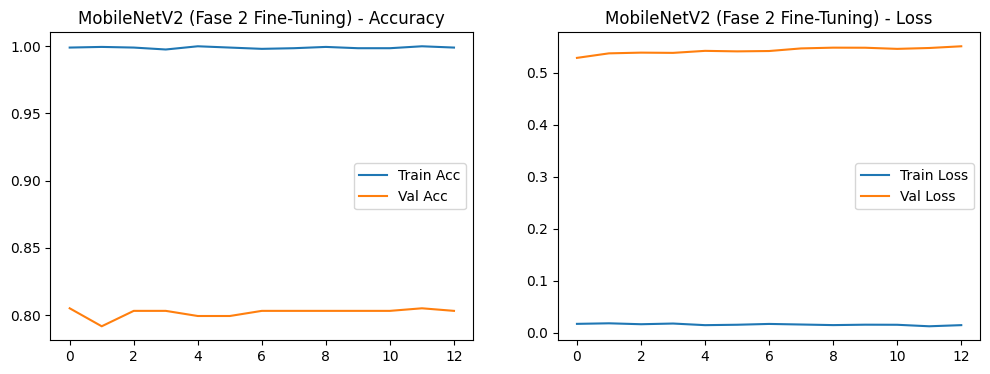

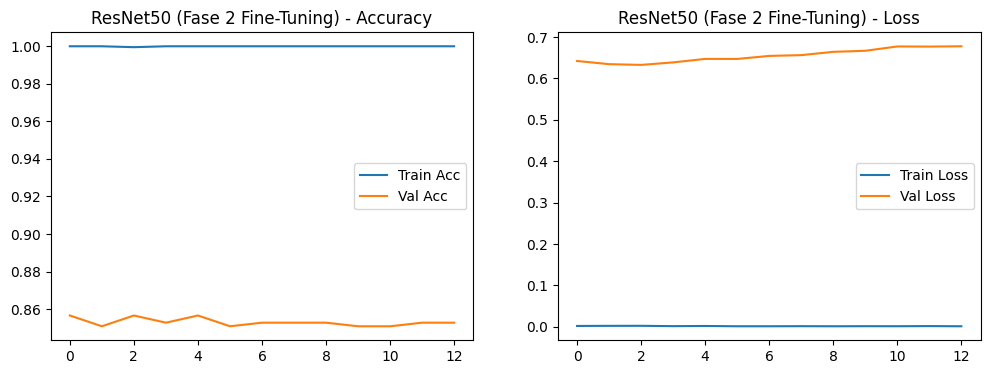

4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step

[INFO] Menggambar Grafik Matriks Lintas Domain Pasar Tradisional...


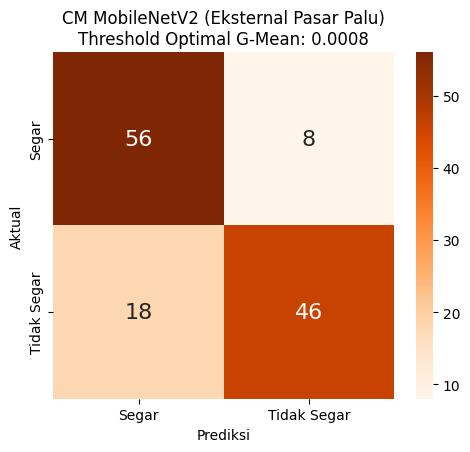

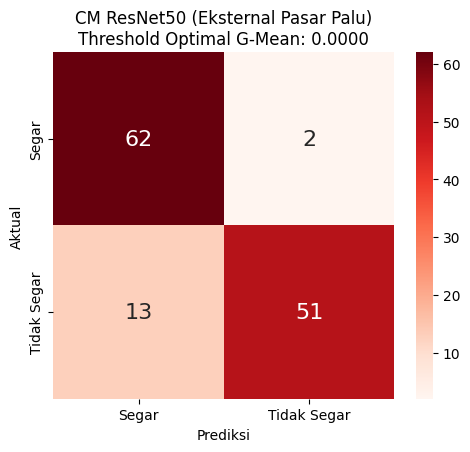


[INFO] Menggambar Kurva ROC Perbandingan Fase 2 Uji Eksternal...


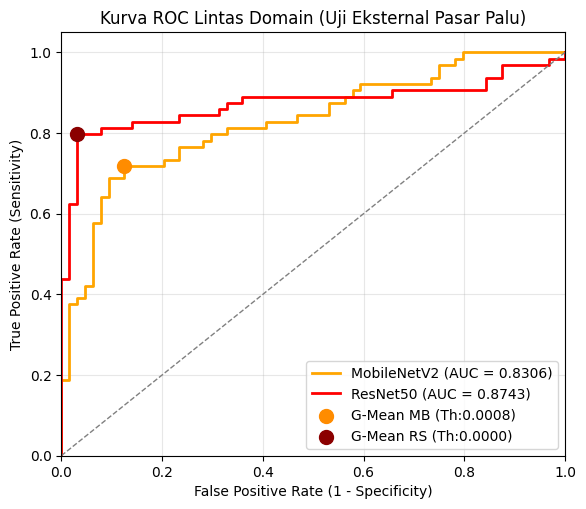

In [ ]:
# SEL 9A: 📊 [VISUALISASI FASE 2] Kurva Fine-Tuning, CM, & Kurva ROC Lintas Domain (G-Mean)


# 4. Menggambar Kurva ROC Perbandingan Lintas Domain (Fase 2)
print("\n[INFO] Menggambar Kurva ROC Perbandingan Fase 2 Uji Eksternal...")
auc_mb_e = auc(fpr_mb_e, tpr_mb_e)
auc_rs_e = auc(fpr_rs_e, tpr_rs_e)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr_mb_e, tpr_mb_e, color='orange', lw=2, label=f'MobileNetV2 (AUC = {auc_mb_e:.4f})')
plt.plot(fpr_rs_e, tpr_rs_e, color='red', lw=2, label=f'ResNet50 (AUC = {auc_rs_e:.4f})')
plt.scatter(fpr_mb_e[idx_mb], tpr_mb_e[idx_mb], color='darkorange', s=100, zorder=5, label=f'G-Mean MB (Th:{th_mb:.4f})')
plt.scatter(fpr_rs_e[idx_rs], tpr_rs_e[idx_rs], color='darkred', s=100, zorder=5, label=f'G-Mean RS (Th:{th_rs:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Kurva ROC Lintas Domain (Uji Eksternal Pasar Palu)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "ROC_Comparison_Fase2_Eksternal.png"), dpi=300, bbox_inches='tight')
plt.show()

# I. Perbandingan MobileNetV2 dan ResNet50

Setelah seluruh evaluasi selesai, performa kedua arsitektur dibandingkan berdasarkan hasil pengujian internal dan eksternal.

Perbandingan digunakan untuk menentukan model yang memiliki performa paling sesuai dengan tujuan penelitian.

In [ ]:
# SEL 9D: 📋 [REKAPITULASI FASE 2] Cetak Laporan Angka Internal & Eksternal

OUTPUT_DIR = '/content/drive/MyDrive/Hasil_Eksperimen_Bandeng'
CLASS_NAMES = ['Segar', 'Tidak Segar']

print("\n" + "="*65)
print("📊 RAPOR INTERNAL DATA VALIDASI KAGGLE SETELAH FINE-TUNING")
print("="*65)

preds_mb_val_f2 = (model_mb.predict(val_dataset).ravel() >= 0.5).astype(int)
df_mb_val_f2 = pd.DataFrame(classification_report(y_true_val, preds_mb_val_f2, target_names=CLASS_NAMES, output_dict=True)).transpose().round(4)
df_mb_val_f2.to_csv(os.path.join(OUTPUT_DIR, "Rekap_Fase2_MobileNetV2_Val_Internal.csv"))
print("\n📋 TABEL MOBILENETV2 (VALIDASI INTERNAL):")
print(df_mb_val_f2.to_string())

preds_rs_val_f2 = (model_rs.predict(val_dataset).ravel() >= 0.5).astype(int)
df_rs_val_f2 = pd.DataFrame(classification_report(y_true_val, preds_rs_val_f2, target_names=CLASS_NAMES, output_dict=True)).transpose().round(4)
df_rs_val_f2.to_csv(os.path.join(OUTPUT_DIR, "Rekap_Fase2_ResNet50_Val_Internal.csv"))
print("\n📋 TABEL RESNET50 (VALIDASI INTERNAL):")
print(df_rs_val_f2.to_string())

print("\n" + "="*65)
print("📊 RAPOR EKSTERNAL PASAR TRADISIONAL KOTA PALU (FINAL)")
print("="*65)

df_mb_ext = pd.DataFrame(classification_report(y_true_ext, y_pred_mb_ext, target_names=CLASS_NAMES, output_dict=True)).transpose().round(4)
df_mb_ext.loc['optimal_threshold'] = [th_mb, th_mb, th_mb, th_mb]
df_mb_ext.to_csv(os.path.join(OUTPUT_DIR, "Rekap_Fase2_Eksternal_MobileNetV2.csv"))
print(f"\n📋 TABEL MOBILENETV2 (UJI EKSTERNAL PASAR) [Thresh: {th_mb:.4f}]:")
print(df_mb_ext.to_string())

df_rs_ext = pd.DataFrame(classification_report(y_true_ext, y_pred_rs_ext, target_names=CLASS_NAMES, output_dict=True)).transpose().round(4)
df_rs_ext.loc['optimal_threshold'] = [th_rs, th_rs, th_rs, th_rs]
df_rs_ext.to_csv(os.path.join(OUTPUT_DIR, "Rekap_Fase2_Eksternal_ResNet50.csv"))
print(f"\n📋 TABEL RESNET50 (UJI EKSTERNAL PASAR) [Thresh: {th_rs:.4f}]:")
print(df_rs_ext.to_string())

print("\n🎉 EVALUASI STRUKTUR SELESAI. SILAKAN AMBIL DATANYA!")


📊 RAPOR INTERNAL DATA VALIDASI KAGGLE SETELAH FINE-TUNING


17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 530ms/step

📋 TABEL MOBILENETV2 (VALIDASI INTERNAL):
              precision  recall  f1-score  support
Segar            0.8150  0.7901    0.8023  262.000
Tidak Segar      0.7955  0.8199    0.8075  261.000
accuracy         0.8050  0.8050    0.8050    0.805
macro avg        0.8052  0.8050    0.8049  523.000
weighted avg     0.8053  0.8050    0.8049  523.000
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 421ms/step

📋 TABEL RESNET50 (VALIDASI INTERNAL):
              precision  recall  f1-score   support
Segar            0.8785  0.8282    0.8527  262.0000
Tidak Segar      0.8370  0.8851    0.8603  261.0000
accuracy         0.8566  0.8566    0.8566    0.8566
macro avg        0.8577  0.8567    0.8565  523.0000
weighted avg     0.8578  0.8566    0.8565  523.0000

📊 RAPOR EKSTERNAL PASAR TRADISIONAL KOTA PALU (FINAL)

📋 TABEL MOBILENETV2 (UJI EKSTERNAL PASAR) [Thresh: 0.0008]:
                   precision    recall  f1-score     support
Segar               0.756800  0.875000  

# J. Uji Statistik McNemar

Uji McNemar digunakan untuk membandingkan hasil prediksi dua model klasifikasi pada sampel pengujian yang sama.

Pengujian ini digunakan untuk mengetahui apakah terdapat perbedaan performa prediksi yang signifikan antara MobileNetV2 dan ResNet50.

In [ ]:
def run_mcnemar_test(dataset, model_a, model_b, threshold_a, threshold_b, scenario_name):
    # 1. Ambil ground-truth
    y_true = np.concatenate([y for x, y in dataset], axis=0).flatten()

    # 2. Prediksi
    pred_prob_a = model_a.predict(dataset).flatten()
    y_pred_a = (pred_prob_a > threshold_a).astype(int)

    pred_prob_b = model_b.predict(dataset).flatten()
    y_pred_b = (pred_prob_b > threshold_b).astype(int)

    # 3. Hitung elemen tabel
    b = np.sum((y_pred_a == y_true) & (y_pred_b != y_true))
    c = np.sum((y_pred_a != y_true) & (y_pred_b == y_true))
    a = np.sum((y_pred_a == y_true) & (y_pred_b == y_true))
    d = np.sum((y_pred_a != y_true) & (y_pred_b != y_true))

    # 4. Tampilkan Tabel
    tabel_visual = pd.DataFrame(
        [[a, b], [c, d]],
        columns=['MobileNetV2 Benar', 'MobileNetV2 Salah'],
        index=['ResNet50 Benar', 'ResNet50 Salah']
    )

    print(f"\n==============================================")
    print(f"TABEL KONTINGENSI MCNEMAR: {scenario_name}")
    print(f"==============================================")
    display(tabel_visual)

    # 5. Hitung P-Value
    result = mcnemar([[a, b], [c, d]], exact=False, correction=True)
    print(f"Statistik Uji (Chi-Squared): {result.statistic:.4f}")
    print(f"P-Value: {result.pvalue:.4e}")

    if result.pvalue < 0.05:
        print("✅ KESIMPULAN: P-Value < 0.05. Perbedaan performa SIGNIFIKAN secara statistik.")
    else:
        print("⚠️ KESIMPULAN: P-Value >= 0.05. Perbedaan performa TIDAK signifikan secara statistik.")

# --- EKSEKUSI ---
# A. Skenario Validasi Internal (Threshold Default 0.5)
run_mcnemar_test(dataset=val_dataset,
                 model_a=model_resnet,
                 model_b=model_mobilenet,
                 threshold_a=0.5,
                 threshold_b=0.5,
                 scenario_name="VALIDASI INTERNAL (LABORATORIUM)")

# B. Skenario Uji Eksternal (Threshold G-Mean)
run_mcnemar_test(dataset=external_dataset,
                 model_a=model_resnet,
                 model_b=model_mobilenet,
                 threshold_a=0.0000,
                 threshold_b=0.0008,
                 scenario_name="UJI EKSTERNAL (PASAR TRADISIONAL)")

17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step

TABEL KONTINGENSI MCNEMAR: VALIDASI INTERNAL (LABORATORIUM)


,MobileNetV2 Benar,MobileNetV2 Salah
ResNet50 Benar,387,61
ResNet50 Salah,34,41


Statistik Uji (Chi-Squared): 7.1158
P-Value: 7.6408e-03
✅ KESIMPULAN: P-Value < 0.05. Perbedaan performa SIGNIFIKAN secara statistik.
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 218ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step

TABEL KONTINGENSI MCNEMAR: UJI EKSTERNAL (PASAR TRADISIONAL)


,MobileNetV2 Benar,MobileNetV2 Salah
ResNet50 Benar,46,18
ResNet50 Salah,56,8


Statistik Uji (Chi-Squared): 18.5000
P-Value: 1.6990e-05
✅ KESIMPULAN: P-Value < 0.05. Perbedaan performa SIGNIFIKAN secara statistik.


In [ ]:
# Sel 10: Pengamanan Ganda Model (Manual Save)
model_mb_final_path = os.path.join(OUTPUT_DIR, 'MobileNetV2_Final_Manual_Save.h5')
model_rs_final_path = os.path.join(OUTPUT_DIR, 'ResNet50_Final_Manual_Save.h5')

model_mb.save(model_mb_final_path)
print(f"✅ Model MobileNetV2 (Final State) diamankan di: {model_mb_final_path}")

model_rs.save(model_rs_final_path)
print(f"✅ Model ResNet50 (Final State) diamankan di: {model_rs_final_path}")

print("\n🎉 SELURUH PROSES EKSPERIMEN SELESAI DAN AMAN DI GOOGLE DRIVE! 🎉")

✅ Model MobileNetV2 (Final State) diamankan di: /content/drive/MyDrive/Hasil_Eksperimen_Bandeng/MobileNetV2_Final_Manual_Save.h5
✅ Model ResNet50 (Final State) diamankan di: /content/drive/MyDrive/Hasil_Eksperimen_Bandeng/ResNet50_Final_Manual_Save.h5

🎉 SELURUH PROSES EKSPERIMEN SELESAI DAN AMAN DI GOOGLE DRIVE! 🎉


# K. Interpretabilitas Model dengan Grad-CAM

Grad-CAM digunakan untuk memvisualisasikan area citra yang memberikan kontribusi terhadap keputusan model.

Analisis ini dilakukan terhadap model final untuk membantu memahami bagian citra ikan yang menjadi perhatian model ketika melakukan klasifikasi.

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_504']]
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)
/tmp/ipykernel_625/2600678377.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = plt.cm.get_cmap("jet")


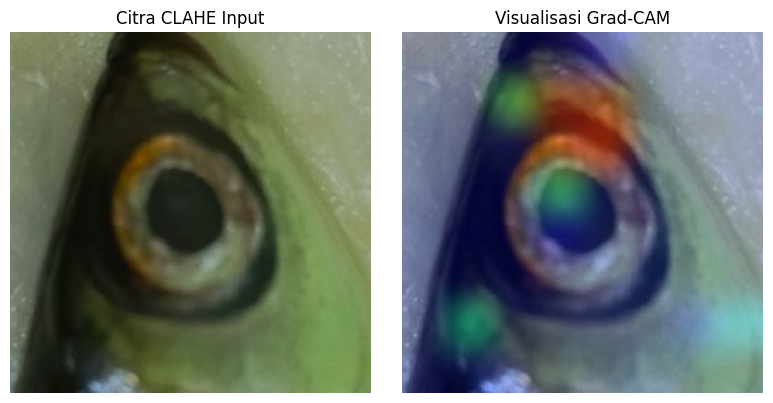

✅ Grad-CAM berhasil di-generate dan disimpan dengan resolusi 300 DPI!


In [ ]:
# ====================================================
# VISUALISASI GRAD-CAM (EXPLAINABLE AI)
# ====================================================
# Fungsi Grad-CAM generik untuk TensorFlow/Keras
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4, filename=None):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (256, 256)) # Sesuai dengan IMG_SIZE Anda

    heatmap = np.uint8(255 * heatmap)
    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = tf.keras.preprocessing.image.array_to_img(superimposed_img)

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.title("Citra CLAHE Input")
    plt.imshow(img)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Visualisasi Grad-CAM")
    plt.imshow(superimposed_img)
    plt.axis('off')

    plt.tight_layout()
    if filename:
        # Resolusi tinggi dpi=300 untuk menjawab kelemahan gambar yang buram
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# --- EKSEKUSI GRAD-CAM ---
# Ambil 1 sampel citra tidak segar dari external test set (Misal indeks ke-0)
# (Sesuaikan path ini dengan salah satu path citra di GDrive Anda)
sample_img_path = '/content/drive/MyDrive/tugas_akhir/data_bandeng_crop/Tidak Segar/IMG_20260614_182152_804.jpg'

# --- START FIX ---
if not os.path.exists(sample_img_path):
    print(f"❌ Error: Image file not found at {sample_img_path}")
    print("Please update 'sample_img_path' with a correct path to an existing image in your Google Drive.")
else:
# --- END FIX ---
    # Preprocessing agar sama dengan saat training (menggunakan fungsi Anda di Sel 3)
    img_raw = cv2.imread(sample_img_path)
    img_raw = cv2.cvtColor(img_raw, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_raw, (256, 256))
    img_clahe = apply_clahe(img_resized) # Fungsi CLAHE milik Anda
    img_array = np.expand_dims(img_clahe, axis=0) # Tambahkan dimensi batch (1, 256, 256, 3)

    # Cari nama layer konvolusi terakhir dari arsitektur backbone.
    # Untuk ResNet50, biasanya bernama 'conv5_block3_out'.
    # Untuk MobileNetV2, biasanya bernama 'out_relu'.
    last_conv_layer_resnet = 'conv5_block3_out'

    # Generate Heatmap
    heatmap = make_gradcam_heatmap(img_array, model_resnet, last_conv_layer_resnet)

    # Tampilkan dan simpan dengan resolusi tinggi (dpi=300)
    display_gradcam(sample_img_path, heatmap, filename="/content/drive/MyDrive/tugas_akhir/gradcam_resnet50.png")
    print("✅ Grad-CAM berhasil di-generate dan disimpan dengan resolusi 300 DPI!")

# L. Penyimpanan dan Ringkasan Model Final

Model yang telah ditetapkan sebagai model terbaik disimpan untuk digunakan pada tahap implementasi atau pengujian lanjutan.

1. Merakit ulang arsitektur ResNet50...
2. Menyuntikkan bobot memori hasil training...
✅ Bobot berhasil dimuat!
3. Memulai prediksi untuk mencari 4 Kondisi (TP, TN, FP, FN)...

✅ Selesai! Gambar berhasil disimpan di: /content/drive/MyDrive/tugas_akhir/Gambar_4_Kondisi_ResNet50.png


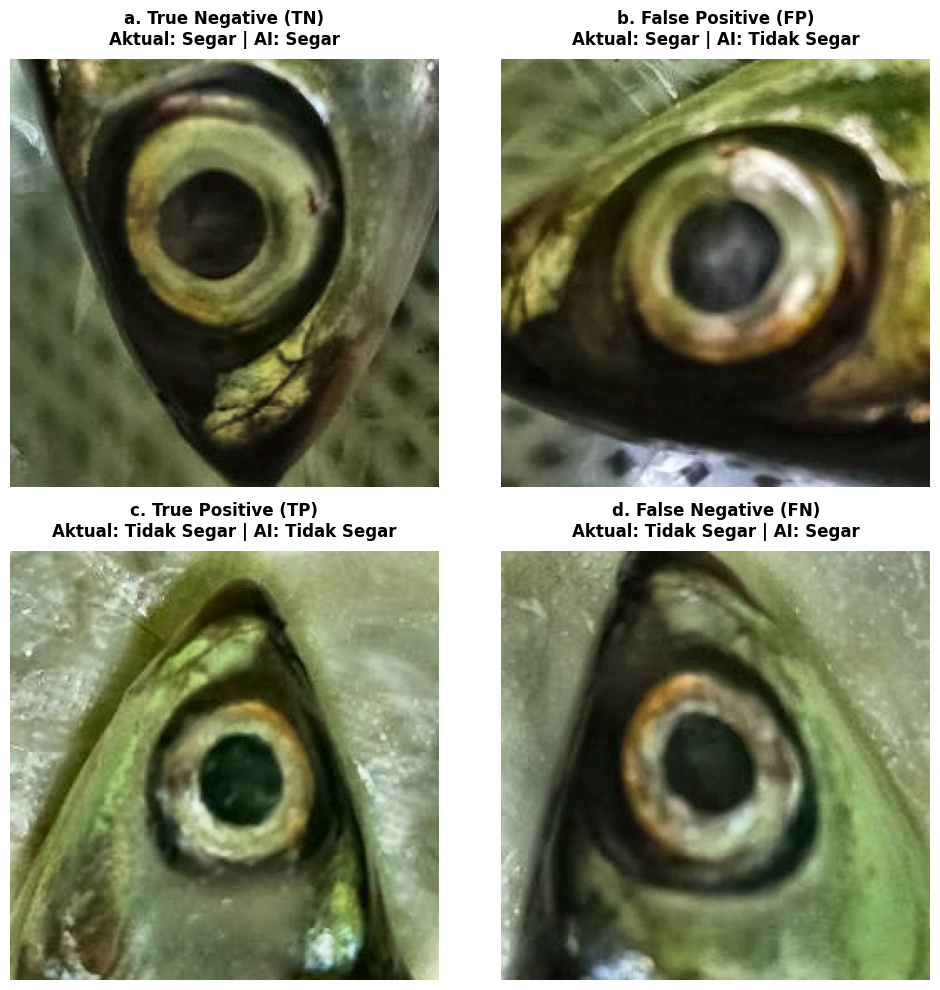

In [ ]:
print("1. Merakit ulang arsitektur ResNet50...")
# Rakit ulang struktur arsitektur (Tanpa bobot ImageNet karena akan diisi bobot Anda)
base_model = tf.keras.applications.ResNet50(weights=None, include_top=False, input_shape=(256, 256, 3))
x = base_model.output
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dropout(0.5)(x)
predictions = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model = tf.keras.models.Model(inputs=base_model.input, outputs=predictions)

print("2. Menyuntikkan bobot memori hasil training...")
# Ganti nama file ini jika Anda ingin menguji MobileNetV2 nantinya
model_path = '/content/drive/MyDrive/tugas_akhir/saved_modelsRS_FineTune_Lokal.h5'
model.load_weights(model_path)
print("✅ Bobot berhasil dimuat!")

print("3. Memulai prediksi untuk mencari 4 Kondisi (TP, TN, FP, FN)...")
y_true = []
y_pred_probs = []
images = []

# Ganti 'external_dataset' dengan nama variabel dataset pasar Anda jika berbeda
for img_batch, label_batch in external_dataset:
    preds = model.predict(img_batch, verbose=0)
    y_pred_probs.extend(preds)
    y_true.extend(label_batch.numpy())
    images.extend(img_batch.numpy())

y_true = np.array(y_true).flatten()
y_pred_probs = np.array(y_pred_probs).flatten()

# Tentukan threshold keputusan (0.5 atau G-Mean)
threshold = 0.5
y_pred = (y_pred_probs > threshold).astype(int)

# 4. Cari Indeks untuk 4 Kondisi (Kelas 0: Segar, Kelas 1: Tidak Segar)
idx_tn = np.where((y_true == 0) & (y_pred == 0))[0]
idx_fp = np.where((y_true == 0) & (y_pred == 1))[0]
idx_tp = np.where((y_true == 1) & (y_pred == 1))[0]
idx_fn = np.where((y_true == 1) & (y_pred == 0))[0]

# 5. Plot Gambar dalam Grid 2x2
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

def plot_img(ax, indices, title):
    if len(indices) > 0:
        img = images[indices[0]]
        # Normalisasi ke 0-1 jika format piksel masih 0-255
        if np.max(img) > 2.0:
            img = img / 255.0
        ax.imshow(img)
        ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    else:
        ax.set_title(title + "\n(Tidak ada contoh ditemukan)", fontsize=12, color='red')
    ax.axis('off')

# Plotting kondisi
plot_img(axes[0, 0], idx_tn, "a. True Negative (TN)\nAktual: Segar | AI: Segar")
plot_img(axes[0, 1], idx_fp, "b. False Positive (FP)\nAktual: Segar | AI: Tidak Segar")
plot_img(axes[1, 0], idx_tp, "c. True Positive (TP)\nAktual: Tidak Segar | AI: Tidak Segar")
plot_img(axes[1, 1], idx_fn, "d. False Negative (FN)\nAktual: Tidak Segar | AI: Segar")

plt.tight_layout()

# Simpan gambar
save_path = '/content/drive/MyDrive/tugas_akhir/Gambar_4_Kondisi_ResNet50.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"\n✅ Selesai! Gambar berhasil disimpan di: {save_path}")
plt.show()